# Why do our readers still make mistakes?

This notebook explains the generalisation audit of **9 November 2026**. It reads saved predictions and original crop previews. **No training, model loading, GPU or downloads.**

We compare S0 (clean baseline), S1 (stage-wise learning rates), and G0 (CTC gradients also reach the backbone). Each recipe has two trained seeds. Their average is a statistic, not an ensemble used by the app.

The aim is to identify a problem before choosing another experiment. We have not demonstrated that more backbone layers or less downsampling would solve the remaining errors.

In [1]:
from pathlib import Path
import json, html, re
from IPython.display import display, HTML, Markdown
import matplotlib.pyplot as plt

roots = [q for p in (Path.cwd(), *Path.cwd().parents) for q in (p, p / 'Assignment')]
A = next(p for p in roots if (p / 'codex_generalisation_audit_20261109/summary.json').is_file())
AUDIT = A / 'codex_generalisation_audit_20261109'
summary = json.loads((AUDIT / 'summary.json').read_text())
sample = json.loads((AUDIT / 'visual_sample.json').read_text())
notes = json.loads((AUDIT / 'visual_notes.json').read_text())['notes']
gallery = (AUDIT / 'review.html').read_text()
print('Audit:', AUDIT)
print(summary['unique_real_crops'], 'real crops; CER checked for six model readings each.')
print(summary['image_metrics_crops'], 'whiteboard-related crop images; 53 selected examples visually inspected.')

def table(headers, rows):
    esc = lambda x: html.escape(str(x))
    display(HTML('<table style="border-collapse:collapse;text-align:left"><tr>' + ''.join('<th style="padding:8px">'+esc(h)+'</th>' for h in headers) + '</tr>' + ''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #ddd">'+esc(v)+'</td>' for v in row)+'</tr>' for row in rows)+'</table>'))

lookup = {(r['set'], r['model']): r for r in summary['summaries']}
sets = ['whiteboard val', 'CNN test', 'long sentences (held out)', 'new writers', 'Jy originals', 'IAM val']
table(['Collection', 'Crops', 'S0 CER', 'S1 CER', 'G0 CER'],
      [[st, lookup[st,'S0']['crops']] + [f"{lookup[st,m]['mean_line_cer']:.2%}" for m in ['S0','S1','G0']] for st in sets])

Audit: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/codex_generalisation_audit_20261109
1801 real crops; CER checked for six model readings each.
825 whiteboard-related crop images; 53 selected examples visually inspected.


Collection,Crops,S0 CER,S1 CER,G0 CER
whiteboard val,136,7.52%,7.09%,7.17%
CNN test,174,25.50%,24.58%,25.70%
long sentences (held out),57,2.36%,2.54%,2.41%
new writers,160,26.79%,24.93%,22.77%
Jy originals,298,7.34%,5.52%,5.64%
IAM val,976,23.89%,23.72%,27.15%


## 1. What does generalisation mean here?

The reader performs well on some handwriting/conditions but much worse on others. The familiar-writer sentence set contains only **seven distinct held-out sentences**. JH/DS covers two unfamiliar writers, while Jy is another user-identified unfamiliar collection.

Differences between these collections involve handwriting, text, margins, lighting and capture conditions together. The table demonstrates uneven performance; it does **not** isolate writer identity as the sole cause. IAM paper handwriting is a separate domain check.

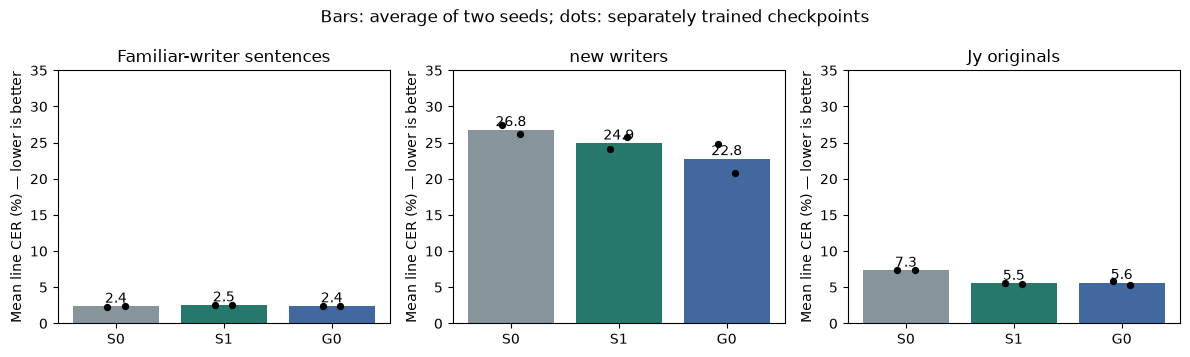

In [2]:
shown = ['long sentences (held out)', 'new writers', 'Jy originals']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, st in zip(axes, shown):
    values = [lookup[st,m]['mean_line_cer'] * 100 for m in ['S0','S1','G0']]
    ax.bar(['S0','S1','G0'], values, color=['#87949c','#26786c','#4169a0'])
    for x, (m, y) in enumerate(zip(['S0','S1','G0'], values)):
        ax.text(x, y+.5, f'{y:.1f}', ha='center')
        ax.scatter([x-.08,x+.08], [v*100 for v in lookup[st,m]['seed_cer']], color='black', s=18, zorder=3)
    ax.set_ylim(0, 35)
    ax.set_title(st.replace('long sentences (held out)', 'Familiar-writer sentences'))
    ax.set_ylabel('Mean line CER (%) — lower is better')
fig.suptitle('Bars: average of two seeds; dots: separately trained checkpoints')
fig.tight_layout()
plt.show()

## 2. What kinds of mistakes remain?

**Deletion:** reference says `cat`, prediction says `ct` (a is missing).
**Substitution:** reference says `cat`, prediction says `cut` (a became u).
**Insertion:** reference says `cat`, prediction says `cart` (extra r).

These are alignments of final strings, not measurements of the internal CTC probabilities. Fractions occur because we average raw edit counts across two seeds. Whole-word empty outputs are rare; missing characters within non-empty readings are much more common on JH/DS.

In [3]:
rows=[]
for r in summary['errors']:
    if r['set'] in ['new writers','Jy originals'] and r['model'] in ['S1','G0']:
        e=r['edit_counts_seed_average']
        rows.append([r['set'],r['model'],e.get('replace',0),e.get('delete',0),e.get('insert',0)])
table(['Collection','Candidate','Substitutions','Deletions','Insertions'], rows)
table(['Collection','Crops at >=15% CER in ALL four S1/G0 checkpoints'],
      [[st,summary['persistent_both_candidates'][st]] for st in ['new writers','Jy originals','CNN test','whiteboard val']])
print('The 15% threshold is an exploratory inspection aid, not a new formal test.')

Collection,Candidate,Substitutions,Deletions,Insertions
new writers,S1,670.5,793.0,112.0
new writers,G0,480.5,919.0,55.0
Jy originals,S1,137.5,24.0,25.5
Jy originals,G0,138.5,22.5,25.5


Collection,Crops at >=15% CER in ALL four S1/G0 checkpoints
new writers,66
Jy originals,22
CNN test,92
whiteboard val,19


The 15% threshold is an exploratory inspection aid, not a new formal test.


## 3. Look at the images before deciding what to change

Choose a review ID below. First inspect the crop and supplied label; expand “Show saved predictions” afterward.

Useful IDs: **1–4** faint short writing/margins; **5–12** readable unfamiliar sentences; **13–24** DS handwriting/margins; **25–26** possible crop/label problems; **27–36** degraded validation/CNN crops; **37–42** hard familiar-writer long lines; **43–48** Jy character confusions; **49–53** low-error controls.

These examples were deliberately selected, mostly for high errors. They illustrate failure types, not how often they occur. Source labels and original scores remain unchanged.

Model,Reading,CER
S0,Possive itig ditotdot e tet,51.3%
S0s2,Pasive itigin dtit ts etet,43.6%
S1,Passivesmitigis dti t t o o e detet,43.6%
S1s2,Passivesisti d oi isigototiet,53.8%
G0,Posive sniftingis ittilt t det,33.3%
G0s2,Padsive snitingi is sittit etest,38.5%

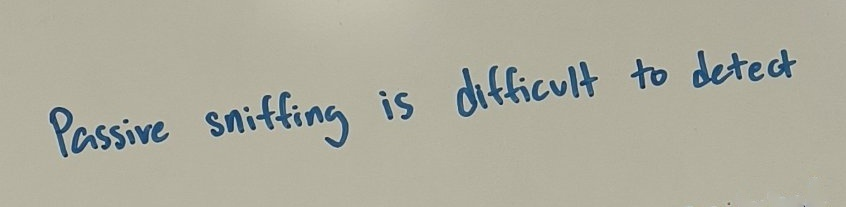

**Assistant observation:** The intended blue sentence writing is readable on inspection, with tilted baselines and variable spacing. Example 10 includes unrelated writing near its upper edge. Both candidates and both seeds make substantial errors.

**Interpretation/limit:** Some failures remain on readable unfamiliar sentences, so poor capture alone is not a sufficient explanation. Perspective, spacing, margins and handwriting are confounded.

In [4]:
def show_case(case_id):
    c = next(c for c in sample if c['review_id'] == case_id)
    match = re.search(r'<article id="case-' + str(case_id) + r'">.*?</article>', gallery, re.S)
    if match is None:
        raise ValueError('Case missing from saved gallery')
    display(HTML(match.group(0)))
    for note in notes:
        if case_id in note['ids']:
            display(Markdown('**Assistant observation:** ' + note['observation'] + '\n\n**Interpretation/limit:** ' + note['interpretation']))

CASE_ID = 5  # Change to any ID from 1 to 53, then rerun this cell.
show_case(CASE_ID)

Model,Reading,CER
S0,Small bird sing soft songs,0.0%
S0s2,Small bird sing soft songs,0.0%
S1,Small bird sing soft songs,0.0%
S1s2,Small bird sing soft songs,0.0%
G0,Small bird sing soft songs,0.0%
G0s2,Small bird sing soft songs,0.0%

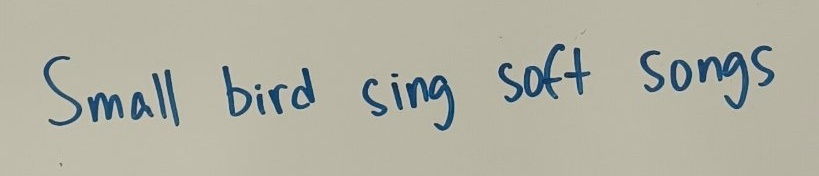

**Assistant observation:** Low-error controls are correctly recognised across both recipes and seeds, including two unfamiliar-writer sentences.

**Interpretation/limit:** Neither unfamiliar handwriting nor sentence length alone determines failure.

In [5]:
# Compare a success from the SAME unfamiliar-writer collection.
show_case(50)

## 4. What do we do next?

The next diagnostic is **original crop versus a safely padded writing-region crop**, using the same frozen reader. Some difficult crops have large margins: resizing the whole crop to 64 px high makes the writing small. That is a testable explanation, not a proven cause.

1. Define writing rectangles from the images, without viewing new predictions; keep all strokes and include success controls.
2. Use the existing S1 seed-1 app default. Compare original and re-cropped readings, deletion/substitution counts, input shapes and regressions. No training is needed.
3. If large-margin cases improve more than tight-crop controls, investigate a practical crop policy or a single scale/margin augmentation in matched training runs. Manual rectangles themselves are an oracle diagnostic, not an automatic application feature.
4. If clear, well-scaled unfamiliar writing still fails, investigate handwriting diversity instead of assuming a bigger backbone is needed.

JH/DS and Jy now inform development. Reserve fresh writer/photo groups before tuning any new model and use those for final confirmation. Full-photo reading order remains a separate pipeline problem.

See the adjacent `codex_generalisation_audit_20261109/ANALYSIS.md` for the full evidence and proposed protocol. This notebook does not run that new inference experiment.